In [1]:
import pandas as pd

df = pd.read_csv("data.csv")
print(df)

    Duration          Date  Pulse  Maxpulse  Calories
0         60  '2020/12/01'    110       130     409.1
1         60  '2020/12/02'    117       145     479.0
2         60  '2020/12/03'    103       135     340.0
3         45  '2020/12/04'    109       175     282.4
4         45  '2020/12/05'    117       148     406.0
5         60  '2020/12/06'    102       127     300.0
6         60  '2020/12/07'    110       136     374.0
7        450  '2020/12/08'    104       134     253.3
8         30  '2020/12/09'    109       133     195.1
9         60  '2020/12/10'     98       124     269.0
10        60  '2020/12/11'    103       147     329.3
11        60  '2020/12/12'    100       120     250.7
12        60  '2020/12/12'    100       120     250.7
13        60  '2020/12/13'    106       128     345.3
14        60  '2020/12/14'    104       132     379.3
15        60  '2020/12/15'     98       123     275.0
16        60  '2020/12/16'     98       120     215.2
17        60  '2020/12/17'  

In [2]:
df.info()
print(df.isna().sum())
print("Duplicates:", df.duplicated().sum())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Duration  32 non-null     int64  
 1   Date      31 non-null     object 
 2   Pulse     32 non-null     int64  
 3   Maxpulse  32 non-null     int64  
 4   Calories  30 non-null     float64
dtypes: float64(1), int64(3), object(1)
memory usage: 1.4+ KB
Duration    0
Date        1
Pulse       0
Maxpulse    0
Calories    2
dtype: int64
Duplicates: 1
         Duration       Pulse    Maxpulse    Calories
count   32.000000   32.000000   32.000000   30.000000
mean    68.437500  103.500000  128.500000  304.680000
std     70.039591    7.832933   12.998759   66.003779
min     30.000000   90.000000  101.000000  195.100000
25%     60.000000  100.000000  120.000000  250.700000
50%     60.000000  102.500000  127.500000  291.200000
75%     60.000000  106.500000  132.250000  343.975000
max    450.000000  130.000000  175

In [3]:
df = df.drop_duplicates().reset_index(drop=True)
print(len(df))

31


In [4]:
df["Date"] = df["Date"].astype(str).str.replace("'", "", regex=False)
df["Date"] = pd.to_datetime(df["Date"], format="mixed", errors="coerce")

print(df["Date"].dtype)
print(df["Date"].isna().sum())

datetime64[ns]
1


In [5]:
print(df[df["Date"].isna()])

df["Date"] = df["Date"].interpolate(method="linear")

print(df.loc[20:22, ["Date", "Duration"]])

    Duration Date  Pulse  Maxpulse  Calories
21        45  NaT    100       119     282.0
         Date  Duration
20 2020-12-21        60
21 2020-12-22        45
22 2020-12-23        60


In [6]:
print(df[df["Duration"] > 120])

df.loc[df["Duration"] > 120, "Duration"] = 45

print(df["Duration"].max())

   Duration       Date  Pulse  Maxpulse  Calories
7       450 2020-12-08    104       134     253.3
60


In [7]:
swap = df["Pulse"] > df["Maxpulse"]
print(df[swap])

df.loc[swap, ["Pulse", "Maxpulse"]] = df.loc[swap, ["Maxpulse", "Pulse"]].values

print(df[swap])

    Duration       Date  Pulse  Maxpulse  Calories
22        60 2020-12-23    130       101     300.0
    Duration       Date  Pulse  Maxpulse  Calories
22        60 2020-12-23    101       130     300.0


In [8]:
print(df[df["Calories"].isna()])

df["Calories"] = df["Calories"].fillna(df.groupby("Duration")["Calories"].transform("mean"))
df["Calories"] = df["Calories"].round(1)

print(df.isna().sum())

    Duration       Date  Pulse  Maxpulse  Calories
17        45 2020-12-18     90       112       NaN
27        60 2020-12-28    103       132       NaN
Duration    0
Date        0
Pulse       0
Maxpulse    0
Calories    0
dtype: int64


In [9]:
df["Calories_per_min"] = (df["Calories"] / df["Duration"]).round(2)
df["Pulse_range"] = df["Maxpulse"] - df["Pulse"]
df["Weekday"] = df["Date"].dt.day_name()
df["Is_Weekend"] = df["Date"].dt.dayofweek >= 5
df["Intensity"] = pd.cut(df["Calories_per_min"], bins=[0, 5, 7, 100], labels=["Low", "Medium", "High"])

print(df.head(10))

   Duration       Date  Pulse  Maxpulse  Calories  Calories_per_min  \
0        60 2020-12-01    110       130     409.1              6.82   
1        60 2020-12-02    117       145     479.0              7.98   
2        60 2020-12-03    103       135     340.0              5.67   
3        45 2020-12-04    109       175     282.4              6.28   
4        45 2020-12-05    117       148     406.0              9.02   
5        60 2020-12-06    102       127     300.0              5.00   
6        60 2020-12-07    110       136     374.0              6.23   
7        45 2020-12-08    104       134     253.3              5.63   
8        30 2020-12-09    109       133     195.1              6.50   
9        60 2020-12-10     98       124     269.0              4.48   

   Pulse_range    Weekday  Is_Weekend Intensity  
0           20    Tuesday       False    Medium  
1           28  Wednesday       False      High  
2           32   Thursday       False    Medium  
3           66    

In [10]:
long_sessions = df[df["Duration"] >= 60]
high_intensity = df[df["Intensity"] == "High"]
weekend_sessions = df[df["Is_Weekend"]]

print(len(long_sessions), len(high_intensity), len(weekend_sessions))
print(high_intensity)

# combining two conditions
long_weekend = df[(df["Duration"] >= 60) & (df["Is_Weekend"])]
print(len(long_weekend))

23 2 8
   Duration       Date  Pulse  Maxpulse  Calories  Calories_per_min  \
1        60 2020-12-02    117       145     479.0              7.98   
4        45 2020-12-05    117       148     406.0              9.02   

   Pulse_range    Weekday  Is_Weekend Intensity  
1           28  Wednesday       False      High  
4           31   Saturday        True      High  
6


In [12]:
high_cal = df[df["Calories"] > 350]
print(len(high_cal))

7


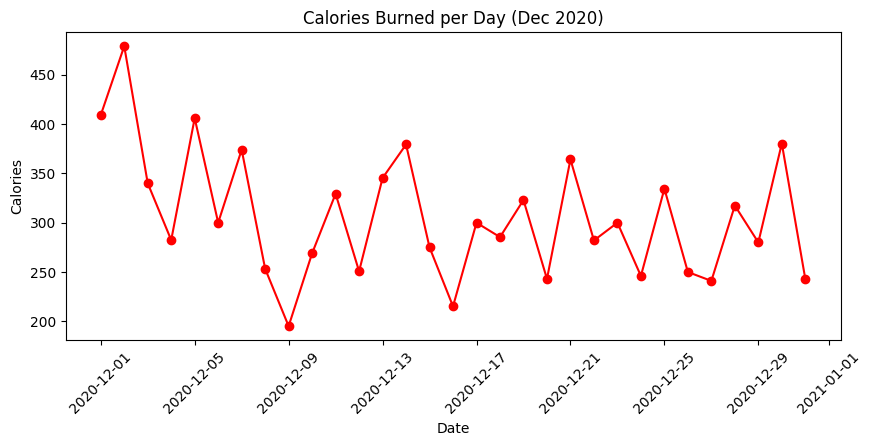

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 4))
plt.plot(df["Date"], df["Calories"], marker="o", color="red")
plt.title("Calories Burned per Day (Dec 2020)")
plt.xlabel("Date")
plt.ylabel("Calories")
plt.xticks(rotation=45)
plt.show()

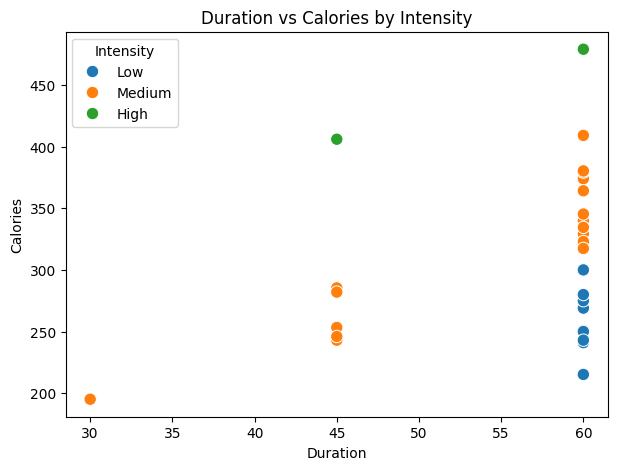

In [14]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Duration", y="Calories", hue="Intensity", s=80)
plt.title("Duration vs Calories by Intensity")
plt.show()

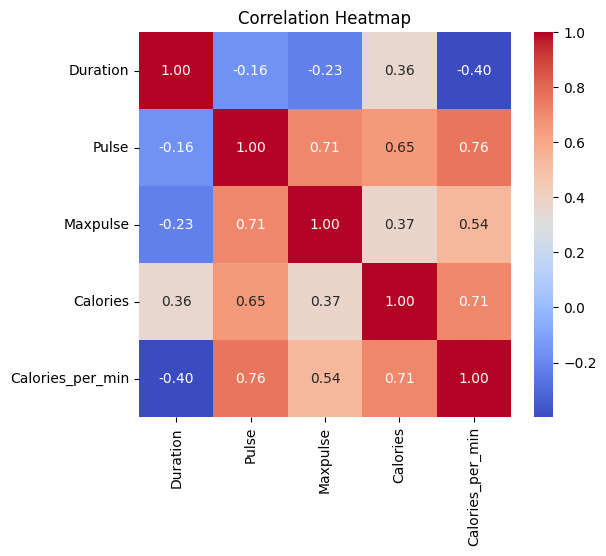

In [15]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[["Duration", "Pulse", "Maxpulse", "Calories", "Calories_per_min"]].corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [16]:
df.to_csv("cleaned_data.csv", index=False)

from google.colab import files
files.download("cleaned_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>